# 02 - Stage 1 (Basic): Logistic Regression

The baseline every later stage must beat. Logistic regression fits one weight
per feature and a bias, passes the weighted sum through a sigmoid, and reads
the output as the probability of ADHD. It is linear, fast, and hard to
overfit with 456 features and ~13,000 training epochs - which makes it the
right yardstick: if a fancier model cannot beat this, the extra machinery is
not earning its keep.

> **Where this fits.** The project is a four-stage progression, every stage
> evaluated the same way so the numbers are directly comparable:
>
> | | Notebook | Stage |
> |---|---|---|
> | 01 | Data and preprocessing | shared by all models |
> | 02 | Logistic Regression | **Stage 1 - Basic** |
> | 03 | Logistic Regression + PCA | **Stage 1 - Basic** |
> | 04 | Random Forest | **Stage 2 - Bagging** |
> | 05 | XGBoost | **Stage 3 - Boosting** |
> | 06 | CNN + LSTM | **Stage 4 - Deep Learning** |
> | 07 | Model comparison | summary |
>
> Run `01` once first - it builds the cache every model notebook loads.

In [1]:
%matplotlib inline
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
np.random.seed(42)

CACHE = "data/epochs.npz"
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"

## Step 1 - Load the preprocessed epochs

**What this does.** Loads the cache written by notebook `01`: every 2-second EEG
window ("epoch"), its 456 hand-engineered features, the label, and - crucially -
the ID of the subject it came from.

**Why the subject ID matters.** Each person contributes many epochs (61 to 336
of them). If epochs from the same person landed in both training and test sets,
the model could score well by recognising the *person* rather than ADHD - the
label is constant within a subject, so recognising the subject gives the label
away. The subject ID is what lets us prevent that in Step 2.

In [2]:
if not os.path.exists(CACHE):
    raise FileNotFoundError("Run 01_Data_and_Preprocessing.ipynb first - it builds " + CACHE)

cache = np.load(CACHE, allow_pickle=True)
X_feat, y, groups = cache["Xf"], cache["y"].astype(int), cache["g"]

# Band powers span several orders of magnitude and are right-skewed; log1p
# compresses that range so no single feature dominates distance-based or
# gradient-based models. Trees are unaffected either way.
X = np.log1p(np.clip(X_feat, 0, None))
X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

subj = pd.DataFrame({"ID": groups, "y": y}).groupby("ID").y.first()
print("epochs   :", X.shape[0])
print("features :", X.shape[1])
print("subjects :", len(subj), "  (%d ADHD, %d Control)" % (subj.sum(), (1 - subj).sum()))

epochs   : 16749
features : 456
subjects : 121   (61 ADHD, 60 Control)


## Step 2 - Build subject-grouped cross-validation folds

**What this does.** Splits the 121 subjects into 5 folds. Each fold holds out
about 24 *people*; all of their epochs go to the test side together.
`StratifiedGroupKFold` keeps the ADHD/Control balance similar across folds.

**Why 5 folds and not one split.** With only 121 subjects, which particular
people end up in the test set changes the score a lot. Five folds give five
estimates, and we report their mean and spread. A single split would hide that
spread entirely.

**Why there is an `assert`.** It is cheap insurance: if a future change ever
lets a subject leak across a split, the notebook stops here instead of quietly
reporting an inflated number.

In [3]:
from sklearn.model_selection import StratifiedGroupKFold

N_SPLITS, SEED = 5, 42
cv = list(StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
          .split(X, y, groups))

for k, (tr, te) in enumerate(cv):
    assert not (set(groups[tr]) & set(groups[te])), "subject leaked across split!"
    print("fold %d: train %5d epochs / %2d subjects   test %4d epochs / %2d subjects"
          % (k, len(tr), len(set(groups[tr])), len(te), len(set(groups[te]))))
print("\nVerified: no subject appears on both sides of any fold.")

fold 0: train 13419 epochs / 97 subjects   test 3330 epochs / 24 subjects
fold 1: train 13412 epochs / 97 subjects   test 3337 epochs / 24 subjects
fold 2: train 13342 epochs / 96 subjects   test 3407 epochs / 25 subjects
fold 3: train 13413 epochs / 97 subjects   test 3336 epochs / 24 subjects
fold 4: train 13410 epochs / 97 subjects   test 3339 epochs / 24 subjects

Verified: no subject appears on both sides of any fold.


## Step 3 - Define how a model is scored

**What this does.** Two helpers used by every model notebook.

- `subject_scores` turns epoch-level predictions into one decision per person
  by **averaging that person's epoch probabilities**, then scores those
  decisions. This is the number that matters: diagnosis happens per person, not
  per 2-second window.
- `save_result` writes the 5-fold summary (and each fold's score) to
  `results.csv` / `results_folds.csv`, which notebook `07` reads.

**Why ROC-AUC alongside accuracy.** Accuracy depends on where the 0.5 cut-off
sits; ROC-AUC measures how well the model *ranks* ADHD subjects above controls,
regardless of the cut-off. Both are reported. The standard deviation is the
sample SD across the 5 folds.

In [4]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix, roc_curve

def subject_scores(g_te, y_te, p):
    """Average epoch probabilities per subject, then score the per-subject decision."""
    s = (pd.DataFrame({"ID": g_te, "y": y_te, "p": p})
         .groupby("ID").agg(y=("y", "first"), p=("p", "mean")))
    pred = (s.p > 0.5).astype(int)
    return roc_auc_score(s.y, s.p), accuracy_score(s.y, pred), f1_score(s.y, pred)

def save_result(model, stage, res, path="results.csv"):
    """Upsert one model's summary row; per-fold rows go to results_folds.csv."""
    row = dict(model=model, stage=stage, n_folds=len(res))
    for c in ("epoch_auc", "subject_auc", "subject_acc", "subject_f1"):
        row[c], row[c + "_sd"] = res[c].mean(), res[c].std()
    for p, new in ((path, pd.DataFrame([row])),
                   (path.replace(".csv", "_folds.csv"), res.assign(model=model, stage=stage))):
        try:
            old = pd.read_csv(p); old = old[old.model != model]
            new = pd.concat([old, new], ignore_index=True)
        except FileNotFoundError:
            pass
        new.sort_values(["stage", "model"]).to_csv(p, index=False)
    print("saved %s -> %s" % (model, path))

print("helpers defined")

helpers defined


## Step 4 - Define the model

**What this does.** A two-step pipeline: standardise every feature to zero mean
and unit variance, then logistic regression.

**Why the scaler lives *inside* the pipeline.** `clone(model).fit(X[tr])`
re-fits the scaler on each fold's training epochs only. Fitting it once on the
whole matrix would let test-fold statistics shape the scaling - a small but
real leak.

**Why `class_weight="balanced"`.** ADHD subjects were recorded longer, so 56%
of epochs are ADHD. Balanced weights stop the model from learning that bias.
`max_iter=2000` just gives the solver room to converge on 456 features.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in 

## Step 5 - Train and evaluate across the 5 folds

**What this does.** For each fold: fit the model on the training subjects'
epochs, predict a probability of ADHD for every test epoch, then score both
per epoch and per subject. Out-of-fold predictions are kept for the plots.

**Why `clone`.** Each fold gets a fresh, unfitted copy of the model so nothing
learned on one fold carries into the next.

In [6]:
from sklearn.base import clone

rows, oof_p, oof_y, oof_g = [], [], [], []
t0 = time.time()
for k, (tr, te) in enumerate(cv):
    m = clone(model)
    m.fit(X[tr], y[tr])
    p = m.predict_proba(X[te])[:, 1]          # P(ADHD) for every test epoch

    ep_auc = roc_auc_score(y[te], p)
    s_auc, s_acc, s_f1 = subject_scores(groups[te], y[te], p)
    rows.append(dict(fold=k, epoch_auc=ep_auc, subject_auc=s_auc,
                     subject_acc=s_acc, subject_f1=s_f1))
    oof_p.append(p); oof_y.append(y[te]); oof_g.append(groups[te])
    print("fold %d  epoch-AUC %.3f | subject-AUC %.3f  subject-acc %.3f"
          % (k, ep_auc, s_auc, s_acc))

res = pd.DataFrame(rows)
oof_p, oof_y, oof_g = map(np.concatenate, (oof_p, oof_y, oof_g))
print("\nLogistic Regression  -  5-fold results  (%.0f s)" % (time.time() - t0))
for c in ["epoch_auc", "subject_auc", "subject_acc", "subject_f1"]:
    print("  %-12s %.3f +- %.3f" % (c, res[c].mean(), res[c].std()))

save_result("Logistic Regression", "1 - Basic", res)

fold 0  epoch-AUC 0.705 | subject-AUC 0.819  subject-acc 0.708


fold 1  epoch-AUC 0.726 | subject-AUC 0.847  subject-acc 0.833


fold 2  epoch-AUC 0.812 | subject-AUC 0.891  subject-acc 0.880


fold 3  epoch-AUC 0.707 | subject-AUC 0.694  subject-acc 0.708


fold 4  epoch-AUC 0.693 | subject-AUC 0.736  subject-acc 0.708

Logistic Regression  -  5-fold results  (16 s)
  epoch_auc    0.729 +- 0.048
  subject_auc  0.798 +- 0.081
  subject_acc  0.768 +- 0.083
  subject_f1   0.788 +- 0.075
saved Logistic Regression -> results.csv


## Step 6 - One decision per subject

**What this does.** Pools the out-of-fold predictions - every subject was in a
test fold exactly once - and makes the final per-person call by averaging that
person's epoch probabilities.

**Why the pooled numbers differ slightly from the fold means.** The fold means
average five scores each computed on about 24 people; the pooled score is
computed once on all 121. Both are legitimate; the fold mean comes with a
spread, which is why the tables quote it.

In [7]:
subject_pred = (pd.DataFrame({"ID": oof_g, "y_true": oof_y, "p": oof_p})
                .groupby("ID").agg(y_true=("y_true", "first"), p_adhd=("p", "mean")))
subject_pred["pred"] = (subject_pred.p_adhd > 0.5).astype(int)
subject_pred["correct"] = subject_pred.pred == subject_pred.y_true

print("Pooled subject-level performance (n = %d)" % len(subject_pred))
print("  accuracy : %.3f" % accuracy_score(subject_pred.y_true, subject_pred.pred))
print("  ROC-AUC  : %.3f" % roc_auc_score(subject_pred.y_true, subject_pred.p_adhd))
print("  F1       : %.3f" % f1_score(subject_pred.y_true, subject_pred.pred))

wrong = subject_pred[~subject_pred.correct].assign(margin=lambda d: (d.p_adhd - .5).abs())
print("\n%d of %d subjects misclassified. Most confident mistakes:" % (len(wrong), len(subject_pred)))
display(wrong.sort_values("margin", ascending=False).head(5).round(3))

Pooled subject-level performance (n = 121)
  accuracy : 0.769
  ROC-AUC  : 0.802
  F1       : 0.788

28 of 121 subjects misclassified. Most confident mistakes:


,y_true,p_adhd,pred,correct,margin
ID,,,,,
v59p,0,0.956,1,False,0.456
v27p,1,0.051,0,False,0.449
v51p,0,0.918,1,False,0.418
v19p,1,0.094,0,False,0.406
v54p,0,0.903,1,False,0.403


## Step 7 - Confusion matrix and ROC curve

**How to read them.** Left column: every 2-second epoch scored on its own.
Right column: one decision per subject. The subject-level matrix has 121 cells
in total - the top-right cell is controls flagged as ADHD, the bottom-left is
ADHD subjects missed. The ROC curve plots sensitivity against false-alarm rate
at every possible cut-off; the area under it is the ROC-AUC quoted above.

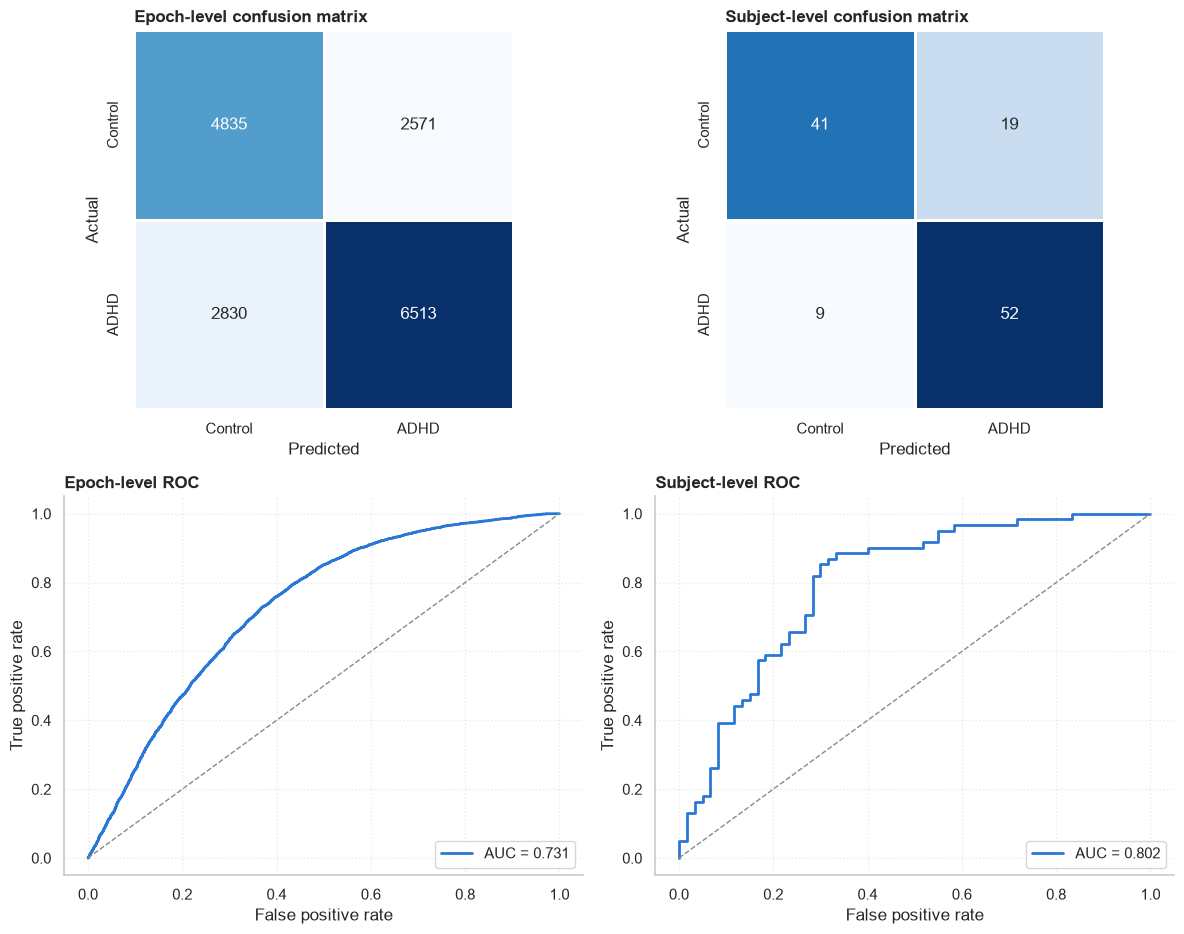

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9.5))
levels = [(oof_y, oof_p, "Epoch"),
          (subject_pred.y_true.values, subject_pred.p_adhd.values, "Subject")]

for col, (yy, pp, lvl) in enumerate(levels):
    cm = confusion_matrix(yy, (pp > 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                linewidths=1, linecolor="white", ax=ax[0, col],
                xticklabels=["Control", "ADHD"], yticklabels=["Control", "ADHD"])
    ax[0, col].set_title("%s-level confusion matrix" % lvl, weight="bold", loc="left")
    ax[0, col].set_xlabel("Predicted"); ax[0, col].set_ylabel("Actual")

    fpr, tpr, _ = roc_curve(yy, pp)
    ax[1, col].plot(fpr, tpr, lw=2, color=BLUE, label="AUC = %.3f" % roc_auc_score(yy, pp))
    ax[1, col].plot([0, 1], [0, 1], "--", color="#8a8a85", lw=1)
    ax[1, col].set_title("%s-level ROC" % lvl, weight="bold", loc="left")
    ax[1, col].set_xlabel("False positive rate"); ax[1, col].set_ylabel("True positive rate")
    ax[1, col].legend(loc="lower right"); ax[1, col].grid(alpha=.4, ls=":")
    for sp in ("top", "right"): ax[1, col].spines[sp].set_visible(False)

plt.tight_layout(); plt.show()

## Step 8 - Which features carry the most weight?

**What this does.** Refits on all data and lists the largest standardised
coefficients. Because inputs are standardised, coefficient size is comparable
across features. Positive pushes towards ADHD, negative towards Control.

**A caution.** Many features are strongly correlated (neighbouring channels,
absolute vs relative power), so weight can shift between correlated features
without changing predictions. Read this as "families that matter", not as a
ranking of individual electrodes.

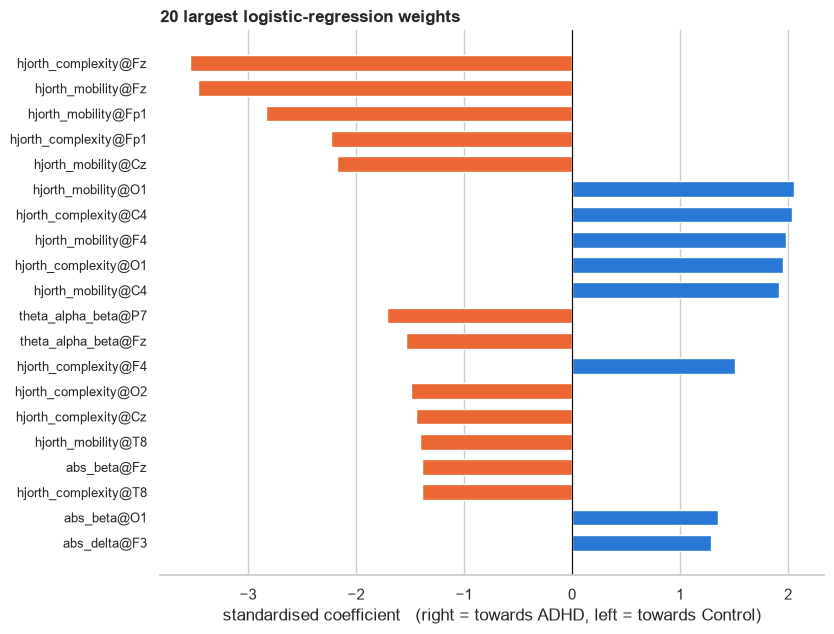

Total |weight| by feature family:
hjorth_mobility      22.959999
hjorth_complexity    21.860001
abs_beta             12.450000
theta_alpha_beta     10.660000
theta_beta            8.590000
rel_delta             7.870000
abs_delta             7.860000
rel_alpha             7.710000
abs_theta             7.060000
abs_alpha             6.630000


In [9]:
names = cache["feature_names"]
final = clone(model).fit(X, y)
coef = pd.Series(final[-1].coef_[0], index=names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index)[:20]

fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.barh(range(len(top))[::-1], top.values, height=.62,
        color=[BLUE if v > 0 else "#eb6834" for v in top.values])
ax.set_yticks(range(len(top))[::-1], top.index, fontsize=9)
ax.axvline(0, color=INK, lw=.8)
ax.set_xlabel("standardised coefficient   (right = towards ADHD, left = towards Control)")
ax.set_title("20 largest logistic-regression weights", weight="bold", loc="left")
ax.grid(axis="y", visible=False)
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

fam = coef.abs().groupby([n.split("@")[0] for n in names]).sum().sort_values(ascending=False)
print("Total |weight| by feature family:"); print(fam.head(10).round(2).to_string())

## Step 9 - How much the score moves from fold to fold

**Why this plot is here.** It is the honest picture of uncertainty. Each pair
of bars is one fold - one particular set of ~24 test subjects. The gap between
the best and worst fold is what a single train/test split would have hidden:
the same model, the same code, and a score that depends on which people were
held out.

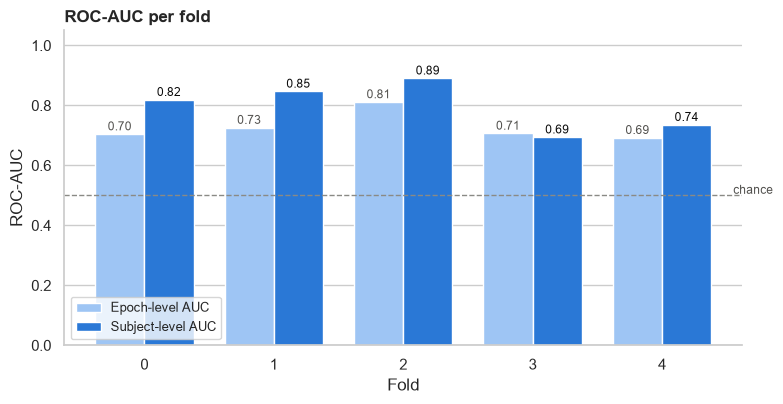

subject-AUC: best fold 0.891, worst fold 0.694, spread 0.197


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
w = .38
ax.bar(res.fold - w/2, res.epoch_auc, w, color="#9ec5f4", label="Epoch-level AUC")
ax.bar(res.fold + w/2, res.subject_auc, w, color=BLUE, label="Subject-level AUC")
for f, e, s in zip(res.fold, res.epoch_auc, res.subject_auc):
    ax.text(f - w/2, e + .012, "%.2f" % e, ha="center", fontsize=8.5, color=MUTED)
    ax.text(f + w/2, s + .012, "%.2f" % s, ha="center", fontsize=8.5, color=INK)
ax.axhline(.5, ls="--", lw=1, color="#8a8a85"); ax.text(4.55, .505, "chance", fontsize=8.5, color=MUTED)
ax.set_ylim(0, 1.05); ax.set_xticks(res.fold); ax.set_xlabel("Fold"); ax.set_ylabel("ROC-AUC")
ax.set_title("ROC-AUC per fold", weight="bold", loc="left")
ax.legend(loc="lower left", fontsize=9); ax.grid(axis="x", visible=False)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

print("subject-AUC: best fold %.3f, worst fold %.3f, spread %.3f"
      % (res.subject_auc.max(), res.subject_auc.min(), res.subject_auc.max() - res.subject_auc.min()))

## How to report this

- Quote the **subject-level** figures **with their +- SD**. With ~24 subjects
  per test fold, one person is worth about 4 percentage points of accuracy, so
  the spread is part of the result.
- Compare against the other stages in `07_Model_Comparison.ipynb`. A model
  whose mean is higher by less than one standard deviation has **not** been
  shown to be better on this data.